# Explore EnCodec window size

Same idea as the *explore window size and overlap* section of `exploring_cs_dataset.ipynb`,
applied to `EncodecCompression` (`src/encodec_compress_vs2.py`) used in `encodec_pipeline_v2.ipynb`.

**Design**
- Windows of **2, 10, 30, 60, 120 s**, with a block (120 s) that is a multiple of every window, so every block splits into whole windows
  (no zero-padded last window) and the window edges fall at the same place for every file.
  With window = block = 120 s, each block is encoded in one call, which is the "no windowing" reference.
- **Several recordings** rather than one long one: ~15 clips of 6 min taken at random offsets from recordings on different days
  (~1.5 h in total). Clip length is a multiple of the block, so there is no partial block.
- Results are reported **per file**, then summarised as mean / spread / boxplots. A paired analysis (same files for every window)
  tests whether the window length matters more than the natural variation between recordings.
- Computational cost (wall time, CPU time, peak RAM, latent size) is measured for each file and window.

How the parameters act in `EncodecCompression`:
- `block_duration_sec`: the audio is processed block by block; each block's windows are held in memory together.
- `window_duration_sec`: each block is split into windows that are encoded **independently**, so artefacts can appear at window edges.
- `batch_size`: number of windows sent to the model at once. It changes compute/memory only, not the codes.

In [1]:
import sys
from pathlib import Path

# Add src/ to sys.path regardless of where Jupyter is launched from
for _candidate in [Path().resolve().parent / "src", Path().resolve() / "src"]:
    if _candidate.exists() and str(_candidate) not in sys.path:
        sys.path.insert(0, str(_candidate))
        print(f"Added to sys.path: {_candidate}")
        break

Added to sys.path: C:\Users\loren\Documents\Postdoc\Compressed_sensing\compressed_sensing_bioacoustics\src


In [2]:
import gc
import math
import shutil
import threading
import time
import numpy as np
import pandas as pd
import psutil
import soundfile as sf
import librosa
import torch
import matplotlib.pyplot as plt
from scipy import stats
from encodec.utils import convert_audio
from skimage.metrics import structural_similarity

from encodec_compress_vs2 import EncodecCompression
from settings import Config
from config_species import get_settings

c:\Users\loren\anaconda3\envs\cs_HeAims\Lib\site-packages\torch\cuda\__init__.py:63: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


## Parameters

In [3]:
TARGET_SPECIES = "PTW"  # Can be Thyolo, PTW, Gibbon
parameter_compression = "6.0"  # Bandwidth (kbps)

data_root = Path("C:/Users/loren/Documents/Postdoc/Compressed_sensing/Data")
folder_audio = data_root / TARGET_SPECIES / "Audio"

# Windows to compare and a block that is a multiple of all of them
WINDOW_DURATIONS = [2, 10, 30, 60, 120]   # seconds
BLOCK_DURATION = math.lcm(*WINDOW_DURATIONS)  # 120 s
BATCH_SIZE = 1
REFERENCE_WINDOW = max(WINDOW_DURATIONS)  # window = block -> no windowing inside the block

# Clips: N_FILES recordings x CLIP_DURATION seconds (aim for 1-2 h in total)
N_FILES = 15
CLIP_DURATION = 3 * BLOCK_DURATION        # 360 s = 6 min, a whole number of blocks
SEED = 0

assert all(BLOCK_DURATION % w == 0 for w in WINDOW_DURATIONS)
assert CLIP_DURATION % BLOCK_DURATION == 0

# Experiment folder (kept outside Audio/ so the pipeline never processes the clips)
folder_experiment = data_root / TARGET_SPECIES / "encodec_window_experiment"
folder_clips = folder_experiment / f"Audio_{CLIP_DURATION}s"
folder_runs = folder_experiment / "runs"
folder_clips.mkdir(parents=True, exist_ok=True)

# Reconstructions take disk space: keep them only for the first clip (used for the visual check)
KEEP_RECONSTRUCTION_FOR_N_FILES = 1

# Mel settings for evaluation come from the species config
settings = get_settings(TARGET_SPECIES.lower())
config = Config(settings)
prep = config.preprocessing
print(prep.dict())
print(f"block={BLOCK_DURATION}s  windows={WINDOW_DURATIONS}  "
      f"{N_FILES} files x {CLIP_DURATION/60:g} min = {N_FILES*CLIP_DURATION/3600:.2f} h")
print("torch threads:", torch.get_num_threads())

{'sample_rate': 48000, 'lowpass_cutoff': 9000, 'downsample_rate': 18400, 'nyquist_rate': 9200, 'segment_duration': 2, 'nb_negative_class': 5, 'annotation_extension': '.svl', 'audio_extension': '.WAV', 'n_fft': 1024, 'hop_length': 256, 'n_mels': 128, 'f_min': 4000, 'f_max': 9000}
block=120s  windows=[2, 10, 30, 60, 120]  15 files x 6 min = 1.50 h
torch threads: 14


## Select the recordings and cut the clips
Recordings are drawn at random (fixed seed) from the whole `Audio/` folder, spread over the recording days,
and each clip starts at a random offset so it is not always the start of a recording.

In [4]:
rng = np.random.default_rng(SEED)

all_files = sorted(f for f in folder_audio.iterdir() if f.suffix.lower() == ".wav")

# Spread the selection over the recording days (file names start with YYYYMMDD)
by_day = {}
for f in all_files:
    by_day.setdefault(f.stem[:8], []).append(f)

days = sorted(by_day)
selected = []
while len(selected) < N_FILES:
    for day in rng.permutation(days):
        remaining = [f for f in by_day[day] if f not in selected]
        if remaining and len(selected) < N_FILES:
            selected.append(remaining[rng.integers(len(remaining))])

clips = []
for f in sorted(selected):
    info = sf.info(f)
    max_start = int(info.duration - CLIP_DURATION)
    start_sec = int(rng.integers(0, max_start + 1))
    clip_file = folder_clips / f"{f.stem}_{start_sec}s.WAV"

    if not clip_file.exists():
        start = start_sec * info.samplerate
        audio, sr_clip = sf.read(f, start=start, stop=start + CLIP_DURATION * info.samplerate, always_2d=True)
        sf.write(clip_file, audio, sr_clip, subtype=info.subtype)

    clips.append(clip_file)

df_clips = pd.DataFrame({
    "clip": [c.name for c in clips],
    "day": [c.stem[:8] for c in clips],
    "hour": [c.stem[9:11] for c in clips],
})
df_clips

,clip,day,hour
0,20210121_142320_613s.WAV,20210121,14
1,20210121_160345_711s.WAV,20210121,16
2,20210121_170400_147s.WAV,20210121,17
3,20210122_032035_75s.WAV,20210122,03
4,20210122_142320_725s.WAV,20210122,14
5,20210122_180415_18s.WAV,20210122,18
6,20210123_034040_455s.WAV,20210123,03
7,20210123_134310_67s.WAV,20210123,13
8,20210123_162350_252s.WAV,20210123,16
9,20210124_050100_404s.WAV,20210124,05


In [5]:
MODEL_SR, MODEL_CHANNELS = 24000, 1   # encodec_model_24khz
sr = MODEL_SR


def load_reference(clip_file):
    '''The clip converted exactly like EncodecCompression does (resampled, mono), so the comparison is sample-aligned.'''
    wav, sr_orig = sf.read(clip_file, always_2d=True)
    wav = torch.from_numpy(wav.T).float()
    return convert_audio(wav, sr_orig, MODEL_SR, MODEL_CHANNELS).squeeze(0).numpy()

## Evaluation metrics

In [6]:
def compute_mse(original, reconstructed):

    length = min(len(original), len(reconstructed))

    original = original[:length]
    reconstructed = reconstructed[:length]

    return np.mean((original - reconstructed) ** 2)

In [7]:
def compute_snr(original, reconstructed):

    length = min(len(original), len(reconstructed))

    original = original[:length]
    reconstructed = reconstructed[:length]

    noise = np.sum((original - reconstructed) ** 2)

    return 10 * np.log10(np.sum(original ** 2) / (noise + 1e-12))

In [8]:
def compute_waveform_corr(original, reconstructed):

    length = min(len(original), len(reconstructed))

    original = original[:length]
    reconstructed = reconstructed[:length]

    return np.corrcoef(original, reconstructed)[0, 1]

In [9]:
def split_audio(audio, sr, window_duration):
    '''Split audio into non-overlapping windows of window_duration seconds.'''

    window_size = int(window_duration * sr)

    n_windows = len(audio) // window_size

    return [
        audio[i * window_size:(i + 1) * window_size]
        for i in range(n_windows)
    ]

In [10]:
def mel_db(x, sr, ref=None):

    mel = librosa.feature.melspectrogram(
        y=x,
        sr=sr,
        n_fft=prep.n_fft,
        hop_length=prep.hop_length,
        n_mels=prep.n_mels,
        fmin=prep.f_min,
        fmax=prep.f_max,
        power=2,
    )

    if ref is None:
        ref = mel.max()

    return librosa.power_to_db(mel, ref=ref), ref

In [11]:
def compute_mel_corr_full(original, reconstructed, sr):
    '''Pearson correlation between the mel spectrograms of the whole recordings.'''

    length = min(len(original), len(reconstructed))

    mel_orig, ref = mel_db(original[:length], sr)
    mel_rec, _ = mel_db(reconstructed[:length], sr, ref=ref)

    return np.corrcoef(mel_orig.ravel(), mel_rec.ravel())[0, 1]

In [12]:
def compute_mean_mel_scores(original, reconstructed, sr, window_duration=prep.segment_duration):
    '''
    Mel correlation and SSIM computed on consecutive windows of the CNN
    segment duration (what the classifier actually sees).
    '''

    length = min(len(original), len(reconstructed))

    windows_original = split_audio(original[:length], sr, window_duration)
    windows_reconstructed = split_audio(reconstructed[:length], sr, window_duration)

    correlations = []
    ssim_scores = []

    for x, y in zip(windows_original, windows_reconstructed):

        mel_x, ref = mel_db(x, sr)
        mel_y, _ = mel_db(y, sr, ref=ref)

        correlations.append(np.corrcoef(mel_x.ravel(), mel_y.ravel())[0, 1])

        # Normalise each spectrogram independently
        mel_x = (mel_x - mel_x.min()) / (mel_x.max() - mel_x.min() + 1e-12)
        mel_y = (mel_y - mel_y.min()) / (mel_y.max() - mel_y.min() + 1e-12)

        ssim_scores.append(structural_similarity(mel_x, mel_y, data_range=1.0))

    return (
        np.mean(correlations), np.std(correlations),
        np.mean(ssim_scores), np.std(ssim_scores),
    )

In [13]:
def compute_boundary_error_ratio(original, reconstructed, sr, window_duration, half_width_ms=10):
    '''
    MSE within +/- half_width_ms of the window edges divided by the MSE elsewhere.
    ~1 = no edge artefact, >1 = errors concentrate at the edges.
    The block is a multiple of the window, so block edges are window edges too.
    '''

    length = min(len(original), len(reconstructed))
    error = (original[:length] - reconstructed[:length]) ** 2

    window_size = int(window_duration * sr)
    boundaries = np.arange(window_size, length, window_size)
    if len(boundaries) == 0:
        return np.nan

    half_width = int(half_width_ms * 1e-3 * sr)
    near = np.zeros(length, dtype=bool)
    for b in boundaries:
        near[max(b - half_width, 0):b + half_width] = True

    return error[near].mean() / (error[~near].mean() + 1e-20)

In [14]:
def evaluate(original, reconstructed, window_duration):

    mel_corr_mean, mel_corr_std, ssim_mean, ssim_std = compute_mean_mel_scores(original, reconstructed, sr)

    return {
        "mse": compute_mse(original, reconstructed),
        "snr_db": compute_snr(original, reconstructed),
        "wave_corr": compute_waveform_corr(original, reconstructed),
        "mel_corr_full": compute_mel_corr_full(original, reconstructed, sr),
        "mel_corr_mean": mel_corr_mean,
        "mel_corr_std": mel_corr_std,
        "ssim_mean": ssim_mean,
        "ssim_std": ssim_std,
        "boundary_error_ratio": compute_boundary_error_ratio(original, reconstructed, sr, window_duration),
    }

## Computational cost monitoring

- **wall time** (`time.perf_counter`) for encode and decode separately, also expressed as seconds of processing per minute of audio.
- **CPU time** (`time.process_time`, all threads of the process) -> average number of cores busy = CPU time / wall time.
- **peak RAM**: the process RSS is sampled every 20 ms in a background thread; we report the peak increase over the RSS just before the step.
  Python/PyTorch keep freed memory for reuse, so within one window size the *first* file usually shows the real increase and the next ones less.
  The summary therefore uses the **max over files** for RAM. For a clean number, restart the kernel and run a single window size.
- **latent size**: bytes of codes (`.bin`) + scales (`.npy`) actually written, i.e. the effective bitrate.

In [15]:
class PeakMemoryMonitor:
    '''Context manager sampling the process RSS in a background thread.'''

    def __init__(self, interval=0.02):
        self.interval = interval
        self.process = psutil.Process()

    def _run(self):
        while not self._stop.is_set():
            self.peak = max(self.peak, self.process.memory_info().rss)
            time.sleep(self.interval)

    def __enter__(self):
        self.baseline = self.process.memory_info().rss
        self.peak = self.baseline
        self._stop = threading.Event()
        self._thread = threading.Thread(target=self._run, daemon=True)
        self._thread.start()
        return self

    def __exit__(self, *exc):
        self._stop.set()
        self._thread.join()
        self.peak = max(self.peak, self.process.memory_info().rss)
        self.peak_increase_mb = (self.peak - self.baseline) / 1e6
        self.peak_mb = self.peak / 1e6


def measure(fn):
    '''Run fn() and return wall time, CPU time and peak RAM.'''

    gc.collect()
    with PeakMemoryMonitor() as mem:
        wall0, cpu0 = time.perf_counter(), time.process_time()
        fn()
        wall, cpu = time.perf_counter() - wall0, time.process_time() - cpu0

    return {
        "wall_s": wall,
        "cpu_s": cpu,
        "cores_used": cpu / wall if wall > 0 else np.nan,
        "peak_ram_increase_mb": mem.peak_increase_mb,
        "peak_ram_mb": mem.peak_mb,
    }

In [16]:
def run_one_file(encodec, clip_file):
    '''Compress + reconstruct one clip with an EncodecCompression instance, from scratch.'''

    # EncodecCompression loops over self.files -> restrict it to this clip to time it alone
    encodec.files = [clip_file.name]

    stem = f"{clip_file.stem}_{encodec.method_compression}_{encodec.parameter_compression}"
    latent_folder = encodec.latent_folder / stem
    reconstructed_file = encodec.compression_folder / f"{stem}.wav"

    # compress() skips files already compressed -> always start clean
    shutil.rmtree(latent_folder, ignore_errors=True)
    reconstructed_file.unlink(missing_ok=True)

    encode = measure(encodec.compress)
    decode = measure(encodec.reconstruct)

    latent_bytes = sum(f.stat().st_size for f in latent_folder.rglob("*") if f.suffix in (".bin", ".npy"))

    cost_stats = {"latent_bytes": latent_bytes}
    cost_stats.update({f"encode_{k}": v for k, v in encode.items()})
    cost_stats.update({f"decode_{k}": v for k, v in decode.items()})

    return cost_stats, latent_folder, reconstructed_file

## Run the experiment
One model instance per window size; every clip is compressed, reconstructed, evaluated and (except the first ones) deleted to save disk space.
Expect roughly 5-10 s of processing per minute of audio and per window size on CPU.

In [17]:
results = []

for window_duration in WINDOW_DURATIONS:

    print("=" * 60)
    print(f"Block={BLOCK_DURATION}s  Window={window_duration}s  Batch={BATCH_SIZE}")

    t0 = time.perf_counter()
    encodec = EncodecCompression(
        folder_clips,
        folder_runs / f"win{window_duration}" / "Compressed_Audio",
        parameter_compression=parameter_compression,
        block_duration_sec=BLOCK_DURATION,
        window_duration_sec=window_duration,
        batch_size=BATCH_SIZE,
    )
    model_load_s = time.perf_counter() - t0

    for i, clip_file in enumerate(clips):

        cost_stats, latent_folder, reconstructed_file = run_one_file(encodec, clip_file)

        original = load_reference(clip_file)
        reconstructed, sr_rec = sf.read(reconstructed_file, dtype="float32")
        assert sr_rec == sr, (sr_rec, sr)

        metrics = evaluate(original, reconstructed, window_duration)

        results.append({
            "file": clip_file.stem,
            "window_duration": window_duration,
            "block_duration": BLOCK_DURATION,
            "batch_size": BATCH_SIZE,
            "audio_duration_s": len(original) / sr,
            "model_load_s": model_load_s,
            **metrics,
            **cost_stats,
        })

        print(f"  {clip_file.stem:28s} encode {cost_stats['encode_wall_s']:6.2f}s  decode {cost_stats['decode_wall_s']:6.2f}s  "
              f"SNR {metrics['snr_db']:5.2f} dB  SSIM {metrics['ssim_mean']:.4f}  "
              f"edge ratio {metrics['boundary_error_ratio']:.2f}")

        if i >= KEEP_RECONSTRUCTION_FOR_N_FILES:
            shutil.rmtree(latent_folder, ignore_errors=True)
            reconstructed_file.unlink(missing_ok=True)

    del encodec
    gc.collect()

df = pd.DataFrame(results)
df["encode_s_per_min"] = df["encode_wall_s"] / df["audio_duration_s"] * 60
df["decode_s_per_min"] = df["decode_wall_s"] / df["audio_duration_s"] * 60
df["effective_kbps"] = df["latent_bytes"] * 8 / df["audio_duration_s"] / 1000
df.to_csv(folder_experiment / "encodec_window_results_per_file.csv", index=False)

Block=120s  Window=2s  Batch=1


c:\Users\loren\anaconda3\envs\cs_HeAims\Lib\site-packages\torch\nn\utils\weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)



Compressing: 20210121_142320_613s.WAV
Encode full file: 10.541836500167847

Reconstructing: 20210121_142320_613s.WAV
Decode full file: 11.29938006401062
  20210121_142320_613s         encode  10.80s  decode  11.33s  SNR  8.05 dB  SSIM 0.0734  edge ratio 0.88

Compressing: 20210121_160345_711s.WAV
Encode full file: 10.732461929321289

Reconstructing: 20210121_160345_711s.WAV
Decode full file: 12.04191517829895
  20210121_160345_711s         encode  10.93s  decode  12.05s  SNR  7.58 dB  SSIM 0.0697  edge ratio 1.04

Compressing: 20210121_170400_147s.WAV
Encode full file: 11.964836597442627

Reconstructing: 20210121_170400_147s.WAV
Decode full file: 12.051166296005249
  20210121_170400_147s         encode  12.21s  decode  12.06s  SNR  6.99 dB  SSIM 0.0722  edge ratio 1.42

Compressing: 20210122_032035_75s.WAV
Encode full file: 11.158650875091553

Reconstructing: 20210122_032035_75s.WAV
Decode full file: 11.397748708724976
  20210122_032035_75s          encode  11.35s  decode  11.41s  SNR

c:\Users\loren\anaconda3\envs\cs_HeAims\Lib\site-packages\torch\nn\utils\weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)



Compressing: 20210121_142320_613s.WAV
Encode full file: 10.577786207199097

Reconstructing: 20210121_142320_613s.WAV
Decode full file: 10.551644086837769
  20210121_142320_613s         encode  10.76s  decode  10.56s  SNR  8.07 dB  SSIM 0.0730  edge ratio 0.78

Compressing: 20210121_160345_711s.WAV
Encode full file: 10.69636583328247

Reconstructing: 20210121_160345_711s.WAV
Decode full file: 10.199493885040283
  20210121_160345_711s         encode  10.91s  decode  10.20s  SNR  7.59 dB  SSIM 0.0682  edge ratio 0.92

Compressing: 20210121_170400_147s.WAV
Encode full file: 10.718823671340942

Reconstructing: 20210121_170400_147s.WAV
Decode full file: 10.473061084747314
  20210121_170400_147s         encode  10.87s  decode  10.48s  SNR  7.04 dB  SSIM 0.0729  edge ratio 1.37

Compressing: 20210122_032035_75s.WAV
Encode full file: 10.721635580062866

Reconstructing: 20210122_032035_75s.WAV
Decode full file: 10.25138807296753
  20210122_032035_75s          encode  10.92s  decode  10.26s  SNR

## Per-file results

In [18]:
# If the kernel was restarted, reload instead of re-running:
# df = pd.read_csv(folder_experiment / "encodec_window_results_per_file.csv")

QUALITY = ["snr_db", "wave_corr", "mel_corr_mean", "ssim_mean", "boundary_error_ratio"]
COST = ["encode_s_per_min", "decode_s_per_min", "encode_peak_ram_increase_mb", "decode_peak_ram_increase_mb", "effective_kbps"]

df[["file", "window_duration"] + QUALITY + COST].round(4)

,file,window_duration,snr_db,wave_corr,mel_corr_mean,ssim_mean,boundary_error_ratio,encode_s_per_min,decode_s_per_min,encode_peak_ram_increase_mb,decode_peak_ram_increase_mb,effective_kbps
0,20210121_142320_613s,2,8.0474,0.9199,0.1198,0.0734,0.8846,1.7992,1.8883,490.2707,36.8148,6.0560
1,20210121_160345_711s,2,7.5775,0.9106,0.0829,0.0697,1.0431,1.8214,2.0080,132.5138,68.1206,6.0560
2,20210121_170400_147s,2,6.9854,0.8980,0.1112,0.0722,1.4212,2.0351,2.0104,138.2482,45.8342,6.0560
3,20210122_032035_75s,2,1.5662,0.6177,0.2237,0.0922,0.9760,1.8923,1.9015,122.9414,21.1067,6.0560
4,20210122_142320_725s,2,7.0904,0.9002,0.1479,0.0776,0.9260,1.8637,1.9275,134.2300,34.1033,6.0560
...,...,...,...,...,...,...,...,...,...,...,...,...
70,20210124_080145_355s,120,8.3894,0.9259,0.1585,0.0886,0.5128,1.6362,1.6079,104.4398,15.2822,6.0009
71,20210124_134310_339s,120,8.7229,0.9309,0.1173,0.0751,2.4009,1.6193,1.5834,75.4319,22.5812,6.0009
72,20210125_030030_23s,120,0.1508,0.5218,0.1248,0.0643,0.9223,1.5860,1.5285,138.2687,33.5135,6.0009
73,20210125_132305_4s,120,2.3369,0.6906,0.1736,0.1002,0.7999,1.6206,1.5097,109.6008,12.8369,6.0009


In [19]:
# One table per metric: files in rows, windows in columns
for metric in ["ssim_mean", "snr_db", "boundary_error_ratio"]:
    print(f"\n{metric}")
    display(df.pivot(index="file", columns="window_duration", values=metric).round(4))


ssim_mean


window_duration,2,10,30,60,120
file,,,,,
20210121_142320_613s,0.0734,0.0730,0.0742,0.0735,0.0730
20210121_160345_711s,0.0697,0.0682,0.0681,0.0676,0.0680
20210121_170400_147s,0.0722,0.0729,0.0717,0.0712,0.0713
20210122_032035_75s,0.0922,0.0918,0.0907,0.0908,0.0901
20210122_142320_725s,0.0776,0.0767,0.0756,0.0756,0.0760
20210122_180415_18s,0.0683,0.0673,0.0662,0.0666,0.0666
20210123_034040_455s,0.1078,0.1076,0.1070,0.1071,0.1067
20210123_134310_67s,0.0914,0.0921,0.0912,0.0910,0.0909
20210123_162350_252s,0.0877,0.0862,0.0868,0.0861,0.0861



snr_db


window_duration,2,10,30,60,120
file,,,,,
20210121_142320_613s,8.0474,8.0684,8.0239,8.0024,8.0001
20210121_160345_711s,7.5775,7.5858,7.5362,7.5277,7.5268
20210121_170400_147s,6.9854,7.0354,7.0055,6.9982,6.9950
20210122_032035_75s,1.5662,1.4996,1.4710,1.4713,1.4787
20210122_142320_725s,7.0904,7.1455,7.1313,7.0963,7.0882
20210122_180415_18s,1.2010,1.1983,1.1991,1.1985,1.2033
20210123_034040_455s,2.8521,2.7524,2.7389,2.7225,2.7147
20210123_134310_67s,3.4576,3.4489,3.4297,3.4275,3.4148
20210123_162350_252s,-0.9178,-0.9243,-0.9442,-0.9444,-0.9314



boundary_error_ratio


window_duration,2,10,30,60,120
file,,,,,
20210121_142320_613s,0.8846,0.7836,0.8797,0.6332,1.0659
20210121_160345_711s,1.0431,0.9232,1.2603,0.9633,1.3522
20210121_170400_147s,1.4212,1.3714,0.8679,1.1144,1.9463
20210122_032035_75s,0.9760,1.2861,2.2032,4.3896,0.7323
20210122_142320_725s,0.9260,1.1753,1.0248,0.9269,1.4100
20210122_180415_18s,0.9915,0.9776,1.0365,1.5566,2.9790
20210123_034040_455s,0.9173,1.1806,0.5211,0.7163,1.1856
20210123_134310_67s,1.4260,1.1801,0.5599,0.6793,0.6391
20210123_162350_252s,0.5862,0.0682,0.0755,0.0595,0.0390


## Summary across files
Mean, standard deviation, median and interquartile range over the recordings, for each window.

In [20]:
def iqr(x):
    return x.quantile(0.75) - x.quantile(0.25)

summary = df.groupby("window_duration")[QUALITY + ["encode_s_per_min", "decode_s_per_min"]].agg(["mean", "std", "median", iqr])

# RAM: max over files (see the note in the monitoring section)
ram = df.groupby("window_duration")[["encode_peak_ram_increase_mb", "decode_peak_ram_increase_mb"]].max()
ram.columns = pd.MultiIndex.from_product([ram.columns, ["max"]])

summary = pd.concat([summary, ram], axis=1)
summary.to_csv(folder_experiment / "encodec_window_results_summary.csv")
summary.round(4).T

window_duration                          2         10        30        60   \
snr_db                      mean      4.1795    4.1798    4.1541    4.1457   
                            std       3.2634    3.2924    3.2918    3.2901   
                            median    3.1317    3.1371    3.1230    3.1257   
                            iqr       5.5971    5.6310    5.6135    5.6159   
wave_corr                   mean      0.7369    0.7371    0.7360    0.7357   
                            std       0.1929    0.1931    0.1933    0.1933   
                            median    0.7429    0.7450    0.7442    0.7448   
                            iqr       0.2679    0.2682    0.2680    0.2690   
mel_corr_mean               mean      0.1647    0.1668    0.1678    0.1681   
                            std       0.0620    0.0615    0.0606    0.0604   
                            median    0.1555    0.1571    0.1584    0.1586   
                            iqr       0.0851    0.0842    0.0829    0.0818   
ssim_mean                   mean      0.0879    0.0872    0.0865    0.0865   
                            std       0.0179    0.0181    0.0181    0.0183   
                            median    0.0877    0.0862    0.0868    0.0861   
                            iqr       0.0234    0.0228    0.0224    0.0233   
boundary_error_ratio        mean      1.0713    1.1296    1.3136    1.8586   
                            std       0.2247    0.4704    1.2757    2.7950   
                            median    1.0235    1.1753    0.9901    0.9633   
                            iqr       0.2389    0.4214    0.4966    0.7722   
encode_s_per_min            mean      1.8628    1.8067    1.6237    1.5893   
                            std       0.0569    0.0190    0.0215    0.0475   
                            median    1.8611    1.8090    1.6283    1.5769   
                            iqr       0.0463    0.0158    0.0298    0.0278   
decode_s_per_min            mean      1.9158    1.7175    1.6804    1.6790   
                            std       0.0429    0.0239    0.0975    0.1971   
                            median    1.9019    1.7097    1.6584    1.6218   
                            iqr       0.0377    0.0274    0.0297    0.0417   
encode_peak_ram_increase_mb max     490.2707  165.6013  200.2125  450.6624   
decode_peak_ram_increase_mb max      68.1206   88.4982  211.3126  141.4595   

window_duration                          120  
snr_db                      mean      4.1432  
                            std       3.2876  
                            median    3.1231  
                            iqr       5.6006  
wave_corr                   mean      0.7357  
                            std       0.1931  
                            median    0.7446  
                            iqr       0.2682  
mel_corr_mean               mean      0.1680  
                            std       0.0602  
                            median    0.1585  
                            iqr       0.0820  
ssim_mean                   mean      0.0864  
                            std       0.0183  
                            median    0.0861  
                            iqr       0.0234  
boundary_error_ratio        mean      3.0681  
                            std       6.6638  
                            median    1.1856  
                            iqr       1.4075  
encode_s_per_min            mean      1.6145  
                            std       0.0441  
                            median    1.6193  
                            iqr       0.0429  
decode_s_per_min            mean      1.5752  
                            std       0.0478  
                            median    1.5750  
                            iqr       0.0596  
encode_peak_ram_increase_mb max     834.9573  
decode_peak_ram_increase_mb max      46.3667

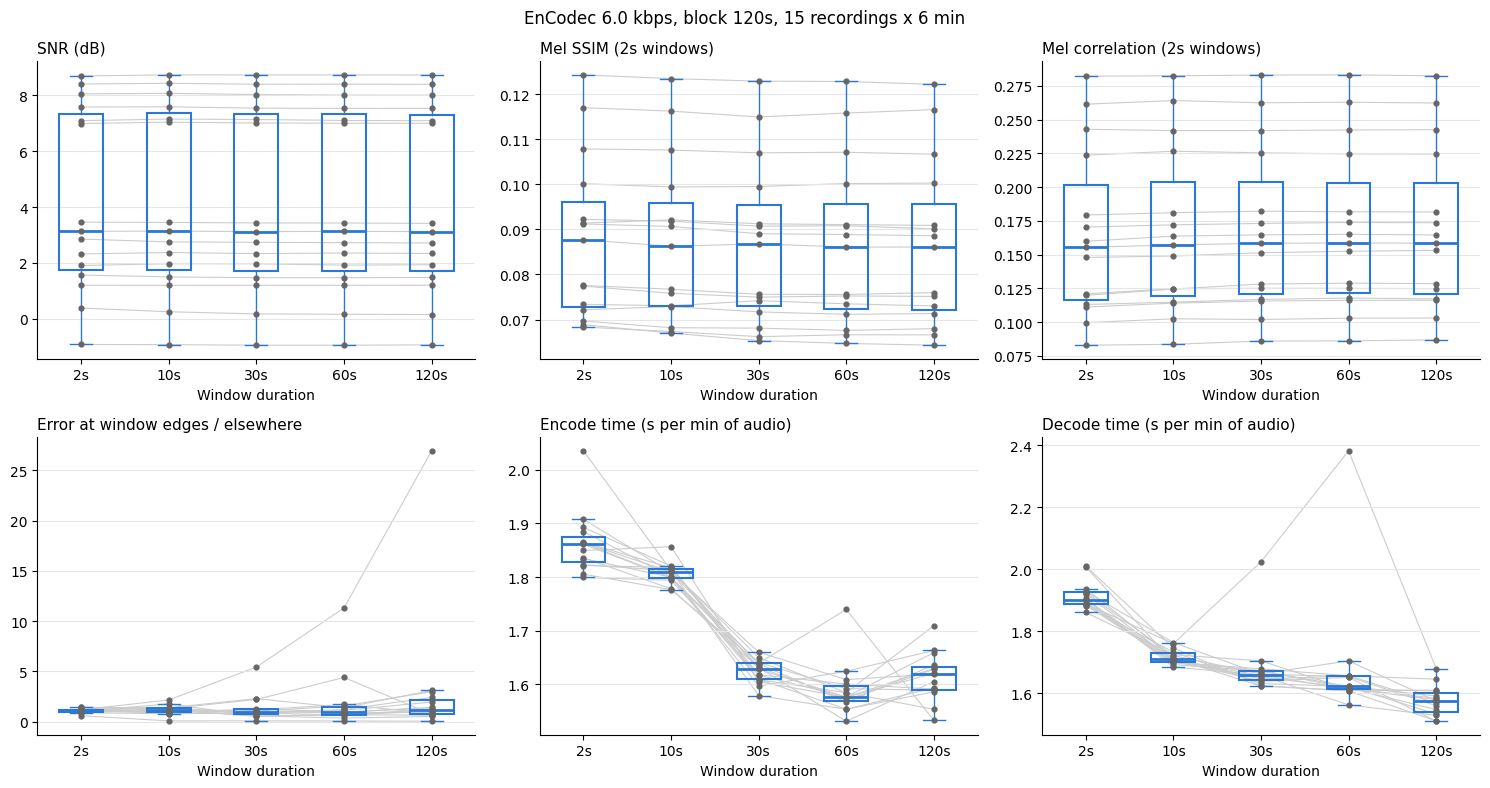

In [21]:
# Boxplots across files. Each gray line is one recording, so you can see whether
# a window change moves every file the same way (window effect) or the spread
# between recordings dominates (natural variation).
panels = [
    ("snr_db", "SNR (dB)"),
    ("ssim_mean", f"Mel SSIM ({prep.segment_duration}s windows)"),
    ("mel_corr_mean", f"Mel correlation ({prep.segment_duration}s windows)"),
    ("boundary_error_ratio", "Error at window edges / elsewhere"),
    ("encode_s_per_min", "Encode time (s per min of audio)"),
    ("decode_s_per_min", "Decode time (s per min of audio)"),
]
BOX_COLOR = "#2a78d6"
positions = np.arange(len(WINDOW_DURATIONS))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, (col, label) in zip(axes.ravel(), panels):

    wide = df.pivot(index="file", columns="window_duration", values=col)[WINDOW_DURATIONS]

    for _, row in wide.iterrows():
        ax.plot(positions, row.values, color="0.8", linewidth=0.8, zorder=1)

    ax.boxplot(
        [wide[w].dropna() for w in WINDOW_DURATIONS], positions=positions, widths=0.5,
        patch_artist=True, showfliers=False, zorder=2,
        boxprops=dict(facecolor="none", edgecolor=BOX_COLOR, linewidth=1.5),
        medianprops=dict(color=BOX_COLOR, linewidth=2),
        whiskerprops=dict(color=BOX_COLOR), capprops=dict(color=BOX_COLOR),
    )
    ax.scatter(np.repeat(positions, len(wide)), wide.T.values.ravel(), s=12, color="0.4", zorder=3)

    ax.set_xticks(positions, [f"{w}s" for w in WINDOW_DURATIONS])
    ax.set_xlabel("Window duration")
    ax.set_title(label, loc="left", fontsize=11)
    ax.grid(True, axis="y", color="0.9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(f"EnCodec {parameter_compression} kbps, block {BLOCK_DURATION}s, "
             f"{df['file'].nunique()} recordings x {CLIP_DURATION/60:g} min")
fig.tight_layout()
plt.show()

## Does the window length matter more than the variation between recordings?

The same recordings are used for every window, so the comparison is **paired**:
1. **Paired difference vs the reference window** (window = block, no windowing inside a block): for each file, metric(window) − metric(reference).
   Its mean and 95 % CI are compared with the **spread between recordings** (std across files at the reference window).
   `effect / file spread` well below 1 means the window effect is small compared with natural variation.
2. **Variance decomposition** (two-way ANOVA without replication, file × window): share of the total variance explained by the window, by the file, and residual.
3. **Friedman test** (non-parametric repeated measures): is there any difference between windows at all?

In [ ]:
def paired_vs_reference(df, metric, reference=REFERENCE_WINDOW):

    wide = df.pivot(index="file", columns="window_duration", values=metric).dropna()
    file_spread = wide[reference].std(ddof=1)

    rows = []
    for w in WINDOW_DURATIONS:
        if w == reference:
            continue
        delta = wide[w] - wide[reference]
        n = len(delta)
        ci = stats.t.ppf(0.975, n - 1) * delta.std(ddof=1) / np.sqrt(n)
        p = stats.wilcoxon(delta).pvalue if n > 5 and np.any(delta != 0) else np.nan
        rows.append({
            "window": w,
            "mean_delta": delta.mean(),
            "ci95_low": delta.mean() - ci,
            "ci95_high": delta.mean() + ci,
            "files_worse": int((delta < 0).sum()) if metric != "boundary_error_ratio" else int((delta > 0).sum()),
            "n_files": n,
            "file_spread_std": file_spread,
            "effect_over_file_spread": abs(delta.mean()) / file_spread,
            "wilcoxon_p": p,
        })

    return pd.DataFrame(rows)


def variance_decomposition(df, metric):

    wide = df.pivot(index="file", columns="window_duration", values=metric).dropna()
    y = wide.values
    n_files, n_windows = y.shape
    grand = y.mean()

    ss_file = n_windows * ((y.mean(axis=1) - grand) ** 2).sum()
    ss_window = n_files * ((y.mean(axis=0) - grand) ** 2).sum()
    ss_total = ((y - grand) ** 2).sum()
    ss_resid = ss_total - ss_file - ss_window

    friedman_p = stats.friedmanchisquare(*[wide[w] for w in wide.columns]).pvalue

    return {
        "metric": metric,
        "pct_var_window": 100 * ss_window / ss_total,
        "pct_var_file": 100 * ss_file / ss_total,
        "pct_var_residual": 100 * ss_resid / ss_total,
        "friedman_p": friedman_p,
    }

In [ ]:
for metric in ["ssim_mean", "mel_corr_mean", "snr_db"]:
    print(f"\n{metric}  (reference window = {REFERENCE_WINDOW}s)")
    display(paired_vs_reference(df, metric).round(4))

In [ ]:
pd.DataFrame([variance_decomposition(df, m) for m in ["snr_db", "wave_corr", "mel_corr_mean", "ssim_mean"]]).round(4)

In [ ]:
# Paired differences vs the reference window, one point per recording
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
others = [w for w in WINDOW_DURATIONS if w != REFERENCE_WINDOW]

for ax, metric in zip(axes, ["ssim_mean", "mel_corr_mean", "snr_db"]):

    wide = df.pivot(index="file", columns="window_duration", values=metric).dropna()
    deltas = [wide[w] - wide[REFERENCE_WINDOW] for w in others]
    spread = wide[REFERENCE_WINDOW].std(ddof=1)

    ax.axhspan(-spread, spread, color="0.93", zorder=0, label="±1 std between recordings")
    ax.axhline(0, color="0.5", linewidth=1)
    for i, d in enumerate(deltas):
        ax.scatter(np.full(len(d), i) + rng.uniform(-0.1, 0.1, len(d)), d, s=14, color="0.4", zorder=2)
        ax.errorbar(i, d.mean(), yerr=stats.sem(d) * stats.t.ppf(0.975, len(d) - 1),
                    fmt="o", color=BOX_COLOR, markersize=8, capsize=4, linewidth=2, zorder=3)

    ax.set_xticks(range(len(others)), [f"{w}s" for w in others])
    ax.set_xlabel("Window duration")
    ax.set_title(f"{metric}: window − {REFERENCE_WINDOW}s", loc="left", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].legend(frameon=False, loc="lower left")
fig.tight_layout()
plt.show()

## Computational cost per window

In [ ]:
cost = df.groupby("window_duration").agg(
    encode_s_per_min_mean=("encode_s_per_min", "mean"),
    encode_s_per_min_std=("encode_s_per_min", "std"),
    decode_s_per_min_mean=("decode_s_per_min", "mean"),
    decode_s_per_min_std=("decode_s_per_min", "std"),
    encode_cores_used=("encode_cores_used", "mean"),
    encode_peak_ram_mb_max=("encode_peak_ram_increase_mb", "max"),
    decode_peak_ram_mb_max=("decode_peak_ram_increase_mb", "max"),
    effective_kbps=("effective_kbps", "mean"),
)
cost["hours_per_100h_audio"] = (cost["encode_s_per_min_mean"] + cost["decode_s_per_min_mean"]) * 60 * 100 / 3600
cost.round(3)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
labels = [f"{w}s" for w in WINDOW_DURATIONS]

axes[0].bar(labels, cost["encode_s_per_min_mean"] + cost["decode_s_per_min_mean"], color=BOX_COLOR, width=0.6)
axes[0].set_title("Encode + decode time (s per min of audio)", loc="left", fontsize=11)

axes[1].bar(labels, cost[["encode_peak_ram_mb_max", "decode_peak_ram_mb_max"]].max(axis=1), color=BOX_COLOR, width=0.6)
axes[1].set_title("Peak RAM increase (MB, max over files)", loc="left", fontsize=11)

for ax in axes:
    ax.set_xlabel("Window duration")
    ax.grid(True, axis="y", color="0.9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Visual check around a window edge
Mel spectrogram of the original vs reconstruction centred on a window edge, for the first clip (its reconstructions are kept).

In [ ]:
window_to_inspect = 10    # seconds, must be in WINDOW_DURATIONS
edge_index = 1            # which edge (1 = first edge after the start)
context_sec = 1.0         # seconds shown on each side of the edge

clip_file = clips[0]
original = load_reference(clip_file)
reconstructed, _ = sf.read(next((folder_runs / f"win{window_to_inspect}").rglob(f"{clip_file.stem}_*.wav")), dtype="float32")

edge = int(edge_index * window_to_inspect * sr)
a, b = edge - int(context_sec * sr), edge + int(context_sec * sr)

mel_o, ref = mel_db(original[a:b], sr)
mel_r, _ = mel_db(reconstructed[a:b], sr, ref=ref)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, m, title in zip(axes, [mel_o, mel_r, mel_r - mel_o],
                        ["Original", f"Reconstructed (window {window_to_inspect}s)", "Difference (dB)"]):
    is_diff = title.startswith("Diff")
    im = ax.imshow(m, origin="lower", aspect="auto",
                   extent=[-context_sec, context_sec, 0, m.shape[0]],
                   cmap="RdBu_r" if is_diff else "magma")
    ax.axvline(0, color="k" if is_diff else "white", linestyle="--", linewidth=1)
    ax.set_title(title, loc="left")
    ax.set_xlabel("Time from window edge (s)")
    fig.colorbar(im, ax=ax)
axes[0].set_ylabel("Mel bin")
fig.tight_layout()
plt.show()

t = (np.arange(a, b) - edge) / sr
plt.figure(figsize=(15, 3))
plt.plot(t, original[a:b] - reconstructed[a:b], linewidth=0.8, color=BOX_COLOR)
plt.axvline(0, color="0.5", linestyle="--")
plt.title(f"Waveform error (original − reconstructed), {clip_file.stem}", loc="left")
plt.xlabel("Time from window edge (s)")
plt.show()

In [ ]:
# Uncomment to free disk space once the results are saved
# shutil.rmtree(folder_runs)
# shutil.rmtree(folder_clips)